# Raio-X das notas fiscais de compras do Estado da Bahia

**Base:** notas fiscais eletrônicas emitidas para órgãos do governo da Bahia,
de janeiro de 2020 a setembro de 2026 (1.407.692 notas).

**Fonte:** "Notas Fiscais Eletrônicas (NFe) de Compras Públicas" do Poder Executivo,
produzido pela SEFAZ-BA (SAT/BINFE) e publicado no Portal de Dados Abertos do
Estado da Bahia (https://dados.ba.gov.br/dataset/3c07c799-18c4-492d-85e4-8c8c998c8d9d).
Atualização diária. Arquivo `notasfiscaiseletronicas.csv`, baixado em 09/09/2026.

**Objetivo:** conhecer a base antes de qualquer análise (tamanho, qualidade,
valores, órgãos e comportamento no tempo).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_colwidth", 80)

caminho = r"C:\Users\Karina\Desktop\IA PARA NEGÓCIOS\notasfiscaiseletronicas.csv"

colunas = [
    "CHAVE_NOTA_FISCAL",
    "DATA_EMISSAO",
    "FORNECEDOR",
    "RAZAO_SOCIAL_DESTINATARIO",
    "NATUREZA",
    "VTOTALNOTAFISCAL",
]

notas = pd.read_csv(
    caminho,
    sep=";",
    decimal=",",
    usecols=colunas,
    dtype={
        "CHAVE_NOTA_FISCAL": str,
        "FORNECEDOR": "category",
        "RAZAO_SOCIAL_DESTINATARIO": "category",
        "NATUREZA": "category",
    },
    parse_dates=["DATA_EMISSAO"],
    date_format="%d/%m/%Y",
)

## 1. O que tem na base?

In [2]:
print(notas.shape)
print(notas["DATA_EMISSAO"].min().strftime("%d/%m/%Y"), "a",
      notas["DATA_EMISSAO"].max().strftime("%d/%m/%Y"))
notas.isna().sum()

(1407692, 6)
01/01/2020 a 08/09/2026


CHAVE_NOTA_FISCAL            0
DATA_EMISSAO                 0
FORNECEDOR                   0
RAZAO_SOCIAL_DESTINATARIO    0
NATUREZA                     0
VTOTALNOTAFISCAL             1
dtype: int64

A base analisada tem **1.407.692 notas**, emitidas entre 01/01/2020 e 08/09/2026.
O arquivo original tem 12 colunas; ficaram 6. Saíram as que tinham um valor só
(todas as notas estão "AUTORIZADA"), a que repetia a data (ANO) e as de CPF/CNPJ,
que vêm mascaradas.

Só um valor está vazio: uma nota de bonificação cujo valor (R\$ 7.064,98) ficou
grudado no texto da natureza da operação por causa de uma aspa no arquivo. Ela será
corrigida na etapa 2.

**Importante:** a base se chama **"Notas Fiscais Eletrônicas (NFe) de Compras Públicas"**,
mas, após análise minuciosa, nota-se que nem toda nota é compra. A soma do valor inclui
bonificações, remessas (por conta e ordem, para conserto e para demonstração), retornos,
devoluções e notas de ajuste fiscal, operações que não representam aquisição de
mercadoria. Por isso, neste notebook, a soma da coluna de valor é tratada como
**valor bruto**, e não como total comprado. A seção 3 mostra exemplos.

## 2. Quanto vale uma nota típica?

In [3]:
notas["VTOTALNOTAFISCAL"].describe()

count     1,407,691.00
mean         21,469.01
std         304,532.06
min               0.00
25%             265.00
50%           1,110.00
75%           5,487.93
max     140,086,487.00
Name: VTOTALNOTAFISCAL, dtype: float64

A média por nota é de **21.469 reais**, contra uma mediana de **1.110 reais** (19 vezes
menor). Metade das notas vale menos de 1.110 reais, e 75% valem menos de 5.488 reais.
Poucas notas gigantes, como a maior da base, de 140 milhões de reais, puxam a média
para cima. Por isso, ao longo deste notebook, a mediana descreve melhor a nota típica.

## 3. As maiores notas são compras?

In [4]:
maiores = notas.sort_values("VTOTALNOTAFISCAL", ascending=False)
maiores[["DATA_EMISSAO", "FORNECEDOR", "RAZAO_SOCIAL_DESTINATARIO",
         "NATUREZA", "VTOTALNOTAFISCAL"]].head(10)

,DATA_EMISSAO,FORNECEDOR,RAZAO_SOCIAL_DESTINATARIO,NATUREZA,VTOTALNOTAFISCAL
578520,2020-12-13,Construtora Estrela Dalva Eireli,Secretaria Da Educacao-sec,PRESTAÇÃO DE SERVIÇO,"140,086,487.00"
516561,2024-12-13,Cdel Cia Distribuidora E Editora De Livros Ltda,Secretaria Da Educacao Estado Da Bahia,DEVOL.DE VENDA DE MERC. ADQ. OU RECEBIDA DE TERCEIROS,"69,558,302.00"
967295,2024-12-06,Cdel Cia Distribuidora E Editora De Livros Ltda,Secretaria Da Educacao Estado Da Bahia,LANCTO SIMPLES FATURAMENTO DECORRENTE VENDA ENTREGA FUTURA,"69,558,302.00"
1068645,2025-07-01,Comdados Comercio E Servicos Eletronicos Ltda,Secretaria Da Educacao,VENDA MERCADORIA ADQ. OU RECEB. DE TERCEIROS,"59,692,920.20"
154332,2022-06-17,Intermodal Brasil Logistica,Fundo Estadual De Saude Do Estado Da Bahia,REMESSA POR CONTA E ORDEM,"49,549,336.20"
1348436,2022-11-01,Siemens Mobility Solucoes De Mobili Ltda.,Companhia De Transportes Salvador,VENDA MERC.ADQ.RECEB.DE TERCEIROS,"48,567,769.88"
892040,2021-10-21,R L Sat Antenas Ltda,Fundacao Da Crianca E Adolescente,DEVOLUCAO DE VENDA ADQUIRIDA DE TERCEIROS,"46,530,000.00"
910431,2021-10-15,R L Sat Antenas Ltda,Fundacao Da Crianca E Adolescente,VENDA MERCADORIA TERCEIROS,"46,530,000.00"
1208687,2023-03-20,Intermodal Brasil Logistica,Fundo Estadual De Saude Do Estado Da Bahia,REMESSA POR CONTA E ORDEM,"43,830,708.24"
1311170,2023-03-14,Intermodal Brasil Logistica,Fundo Estadual De Saude Do Estado Da Bahia,REMESSA POR CONTA E ORDEM,"40,311,525.80"


In [5]:
zeradas = notas[notas["VTOTALNOTAFISCAL"] == 0]
print(len(zeradas))
zeradas["NATUREZA"].value_counts().head(10)

988


NATUREZA
VENDA MERCAD.ADQUIR.E/OU RECEB.TERCEIROS    122
CREDITO PRESUMIDO                            48
ESTORNO DE CREDITO                           47
RETORNO RECEBIDO P/ CONSERTO                 43
ENTRADA RECEBIDO P/ CONSERTO                 39
COMPLEMENTAR                                 38
5949                                         38
VENDA                                        33
REMESSA - ENTREGA FUTURA                     31
REMESSA EM BONIFICACAO DOACAO OU BRINDE      23
Name: count, dtype: int64

Das 10 maiores notas da base, **só 2 são compras comuns**. As outras oito mostram por que
a soma da coluna de valor não é o total comprado:

- **Vendas desfeitas:** dois pares de notas com o mesmo valor — uma venda (ou simples
  faturamento) seguida de devolução poucos dias depois. Na prática deram zero; na soma,
  aparecem duas vezes.
- **Remessas por conta e ordem:** três notas de uma empresa de logística, que transporta a
  mercadoria em nome de quem vendeu. A venda está em outra nota.
- **Uma "prestação de serviço" de R\$ 140 milhões**, a maior nota da base, emitida em NF-e,
  que é documento de mercadoria.

No outro extremo, **988 notas têm valor zero**. A maioria é nota de ajuste fiscal (crédito
presumido, estorno de crédito, complemento) ou movimento sem venda (conserto, entrega
futura, bonificação), em que o zero faz sentido. Mas 155 são vendas com valor zero, que
também precisam ser investigadas.

## 4. Quem recebe mais notas?

In [6]:
resumo_orgao = (
    notas
    .groupby("RAZAO_SOCIAL_DESTINATARIO", observed=True)
    .agg(
        notas=("CHAVE_NOTA_FISCAL", "count"),
        total=("VTOTALNOTAFISCAL", "sum"),
        mediana=("VTOTALNOTAFISCAL", "median"),
    )
    .sort_values("total", ascending=False)
)
print(len(resumo_orgao))
resumo_orgao.head(10)

90647


,notas,total,mediana
RAZAO_SOCIAL_DESTINATARIO,,,
Fundo Estadual De Saude Do Estado Da Bahia,173071,"4,533,408,928.55","1,260.94"
Secretaria De Desenvolvimento Urban O,837,"3,048,525,728.39","1,535,110.07"
Secretaria Da Educacao-sec,36749,"1,759,011,645.81","3,196.08"
Policia Militar Da Bahia,51159,"710,165,248.12",528.00
Bahia Secretaria Da Seguranca Publica,9147,"538,934,358.02",570.00
Secretaria De Desenvolv Urbano,206,"523,681,988.70","1,466,634.91"
Bahia Secretaria De Saude Do Estado,2789,"492,346,502.32","14,341.67"
Secretaria Da Educacao - Sec,7284,"466,688,314.04","2,675.37"
Instituto Do Patrimonio Artistico E Cultural Da Bahia,1488,"354,160,208.33","1,843.01"


In [7]:
nome = notas["RAZAO_SOCIAL_DESTINATARIO"]
fundo_saude = nome.str.contains("fundo est", case=False) & nome.str.contains("saude", case=False)

print(nome[fundo_saude].nunique(), "grafias")
print(notas[fundo_saude]["VTOTALNOTAFISCAL"].sum() / 1e9, "bilhões")

4733 grafias
9.119932738740003 bilhões


O agrupamento por órgão encontrou **90.647 nomes diferentes**, mas o governo de um
estado tem algumas centenas de órgãos. A diferença vem das grafias: o mesmo órgão
aparece escrito de muitos jeitos. A Secretaria da Educação, por exemplo, aparece em três
linhas do top 10.

Isso distorce o ranking. O Fundo Estadual de Saúde soma **R\$ 4,5 bilhões** na linha
principal, mas **R\$ 9,1 bilhões** somando todas as suas 4.733 grafias: metade do
valor estava escondida em outras linhas. Os nomes serão padronizados na etapa 2.

A tabela também mostra que os órgãos compram de jeitos diferentes. A maioria tem muitas
notas de valor baixo (mediana de algumas centenas ou poucos milhares de reais), típico de
compra de rotina. A Secretaria de Desenvolvimento Urbano é o oposto: poucas notas, com
mediana acima de **R\$ 1,5 milhão**. Quase todas são da Companhia do Metrô da Bahia,
referentes a serviço de transporte.

## 5. Como o valor se distribui no tempo?

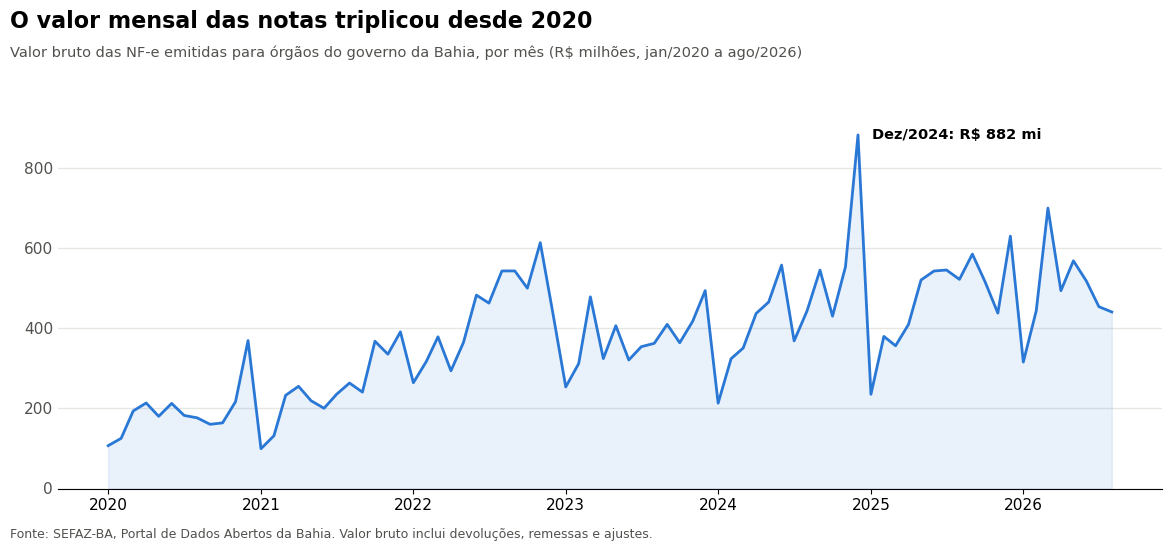

In [8]:
import matplotlib.dates as mdates

AZUL = "#2a78d6"
AZUL_CLARO = "#a9c6ea"
CINZA = "#52514e"
GRADE = "#e6e6e3"
FONTE = "Fonte: SEFAZ-BA, Portal de Dados Abertos da Bahia. Valor bruto inclui devoluções, remessas e ajustes."
plt.rcParams["font.size"] = 11

notas["mes"] = notas["DATA_EMISSAO"].dt.to_period("M")
por_mes = notas.groupby("mes")["VTOTALNOTAFISCAL"].sum() / 1_000_000
por_mes = por_mes.loc[:"2026-08"]

x = por_mes.index.to_timestamp()
pico = por_mes.idxmax()

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(x, por_mes.values, color=AZUL, linewidth=2)
ax.fill_between(x, por_mes.values, color=AZUL, alpha=0.1)

ax.annotate(f"Dez/2024: R$ {por_mes.max():.0f} mi",
            xy=(pico.to_timestamp(), por_mes.max()),
            xytext=(10, 0), textcoords="offset points",
            fontsize=10.5, fontweight="bold", va="center")

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_ylim(0, por_mes.max() * 1.12)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="y", color=GRADE, linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0, labelcolor=CINZA)

fig.text(0.02, 0.97, "O valor mensal das notas triplicou desde 2020",
         fontsize=16, fontweight="bold", va="top")
fig.text(0.02, 0.905, "Valor bruto das NF-e emitidas para órgãos do governo da Bahia, por mês (R$ milhões, jan/2020 a ago/2026)",
         fontsize=10.5, color=CINZA, va="top")
fig.text(0.02, 0.01, FONTE, fontsize=9, color=CINZA)

fig.subplots_adjust(top=0.82, bottom=0.1, left=0.06, right=0.98)
plt.savefig("valor_por_mes.png", dpi=200)
plt.show()

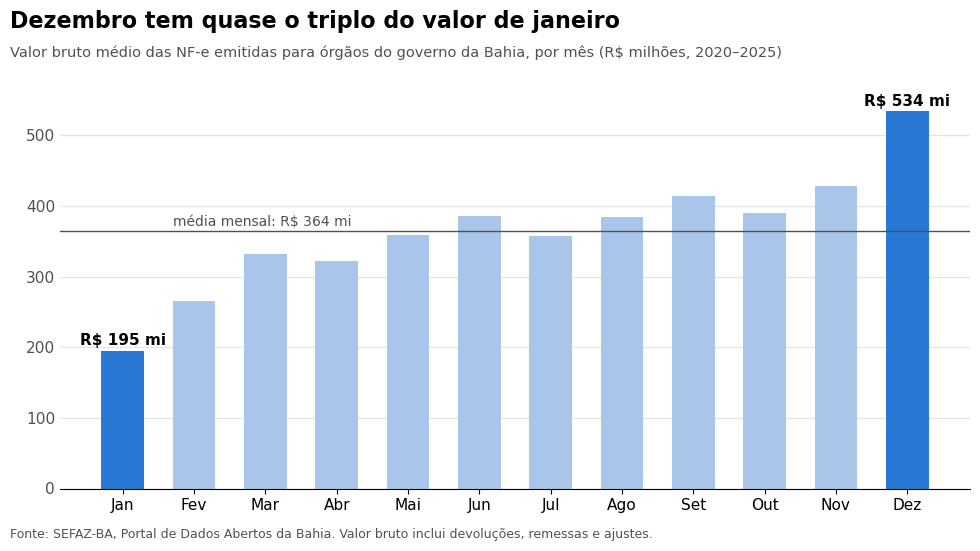

In [9]:
anos_completos = por_mes.loc["2020-01":"2025-12"]
media_por_mes = anos_completos.groupby(anos_completos.index.month).mean()

meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
         "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
media_geral = media_por_mes.mean()
cores = [AZUL if m in (1, 12) else AZUL_CLARO for m in media_por_mes.index]

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(meses, media_por_mes.values, color=cores, width=0.6)

ax.axhline(media_geral, color=CINZA, linewidth=1)
ax.text(0.7, media_geral + 8, f"média mensal: R$ {media_geral:.0f} mi",
        ha="left", fontsize=10, color=CINZA)

for i in (0, 11):
    valor = media_por_mes.values[i]
    ax.text(i, valor + 8, f"R$ {valor:.0f} mi", ha="center",
            fontsize=11, fontweight="bold")

ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="y", color=GRADE, linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0, labelcolor=CINZA)

fig.text(0.02, 0.97, "Dezembro tem quase o triplo do valor de janeiro",
         fontsize=16, fontweight="bold", va="top")
fig.text(0.02, 0.905, "Valor bruto médio das NF-e emitidas para órgãos do governo da Bahia, por mês (R$ milhões, 2020–2025)",
         fontsize=10.5, color=CINZA, va="top")
fig.text(0.02, 0.01, FONTE, fontsize=9, color=CINZA)

fig.subplots_adjust(top=0.82, bottom=0.1, left=0.07, right=0.98)
plt.savefig("sazonalidade.png", dpi=200)
plt.show()

O gráfico de linha mostra que o valor bruto mensal **triplicou** entre 2020 (R\$ 100 a 200
milhões por mês) e 2025–2026 (R\$ 400 a 600 milhões). Os dados não dizem o motivo: pode ser
aumento de gasto, inflação ou mais órgãos entrando na base. Setembro de 2026 ficou de fora
porque o mês está incompleto.

O gráfico de barras mostra o padrão do ano. Na média de 2020 a 2025, **janeiro tem 54% do
valor de um mês médio, e dezembro, 147%**. É o efeito do orçamento anual: o que não é
empenhado até 31 de dezembro, em geral, se perde, e em janeiro o orçamento novo ainda está
começando a ser executado.

O maior mês da base, dezembro de 2024 (R\$ 882 milhões), inclui uma venda de R\$ 69,5
milhões desfeita por devolução uma semana depois: R\$ 139 milhões desse pico não são compra.

## Conclusões e limitações

### O que a base é de verdade

Apesar do nome oficial, esta base não registra apenas compras: ela reúne **todas as notas
fiscais emitidas para órgãos do governo da Bahia**. Das 10 maiores notas, só 2 são vendas
comuns. As outras são vendas desfeitas por devolução, remessas por conta e ordem e uma
"prestação de serviço" de R\$ 140 milhões que precisa ser investigada. Por isso, todos os
totais deste notebook são **valor bruto**, e não o valor efetivamente comprado pelo Estado.

Minha experiência na área fiscal foi decisiva nesse ponto: sem ler a natureza da operação,
o total de R\$ 30,2 bilhões seria facilmente apresentado como "compras do Estado".

### Problemas encontrados

- **Grafias:** o mesmo órgão aparece escrito de muitos jeitos (90.647 nomes diferentes),
  o que divide os totais. O Fundo Estadual de Saúde tem metade do seu valor escondida em
  outras grafias.
- **Natureza da operação sem padrão:** a mesma operação aparece com textos diferentes,
  às vezes separados só por uma barra no final.
- **Notas zeradas:** 988 notas têm valor zero. A maioria é ajuste fiscal ou movimento sem
  venda, mas 155 são vendas com valor zero e precisam ser investigadas.
- **Erro de formato:** uma nota de bonificação perdeu o valor por causa de uma aspa no
  arquivo.

### Diferença em relação à descrição oficial

A base é apresentada como "do Poder Executivo", mas inclui notas do Tribunal de Justiça,
que pertence ao Poder Judiciário. Não foi possível confirmar o motivo apenas com os dados.

### Versão dos dados

Esta análise usa o arquivo baixado em 09/09/2026, com notas até 08/09/2026. A base é
atualizada diariamente, então versões mais recentes terão números diferentes. As próximas
etapas usarão uma versão nova, com data de corte em 30/09/2026.

### Próximos passos

Na próxima etapa vou construir uma base limpa: agrupar as naturezas da operação (venda,
devolução, remessa, ajuste) para separar o que é compra de fato, unificar os nomes de órgãos
e fornecedores, extrair o CNPJ do emitente de dentro da chave de acesso e tratar as notas
suspeitas sem apagá-las, registrando cada decisão.